# Химический состав образцов керамики


Сравним, сколько Na₂O и Al₂O₃ содержится в основе (Body) и глазури (Glaze). Оба вещества измерены в массовых процентах. В CSV 88 строк, по две на каждый из 44 образцов.



В лабораторной работе использовался открытый датасет UC Irvine Machine Learning Repository: https://archive.ics.uci.edu/dataset/583/chemical+composition+of+ceramic+samples Открытый репозиторий представляет нам кассификацию образцов древней китайской керамики - Longquan celadon на основе их химического состава на основе энергодисперсионной рентгеновской флуоресценции. Для изучения сырья и технологии обжига они отобрали 40 типичных осколков, относящихся к четырем культурным эпохам. В таблице представлены процентные содрежания таких соединений как: Na2O, MgO, Al2O3, SiO2, K2O, CaO, TiO2, Fe2O3, MnO, CuO, ZnO, PbO2, Rb2O, SrO, Y2O3, ZrO2, P2O5. Их содержание представлено в основах(body) и в глазури(glaze) остатков.

**Цель исследования**: провести статистический анализ химического состава образцов керамики Longquan celadon; исследовать особенности распредления компонентов в body и glaze; сравнить процентное содержание вещест в body и glaze в рамках 1 осататка керамики.

В рамках данной лабораторной работы мы будем подробно изучать 4 случайные величины: процентное содержание Na2O в body, процентное содержание Na2O в glaze, процентное содержание Al2O3 в body, процентное содержание Al2O3 в glaze. Параметры являются случайными величинами, так как их содержание можно узнать только на основе измерения - энергодисперсионной рентгеновской флуоресценции. Мы не можем знать заранее точное содержание изучаемых оксидов. А образец керамики мы выбиарем случайно. Поэтому мы можем изучать данные случайные величины прикладной математической статистикой.

## Структура исследования

1. [Четыре величины](#rv01)
2. [Зависимость](#dependence)
3. [Выборки и оценки](#sampling)
4. [Гипотеза](#hypothesis)
5. [Выводы](#resume)

## Почему рассматриваем данные как случайные величины

Когда выбираем один образец, у него есть четыре числа, заранее эти числа нельзя. В исходном исследовании значения определили методом рентгенофлуоресцентного анализа. При выборе другого образца значения могут поменяться. Поэтому рассматриваем их как случайные величины.


Строк в CSV: 88. Полных пар: 44. Пропусков в этих четырёх столбцах нет.
Логнормальная модель: p = 0.0137
Гамма-модель: k = 1.4310, θ = 0.3815
D = 0.0754, p = 0.7605


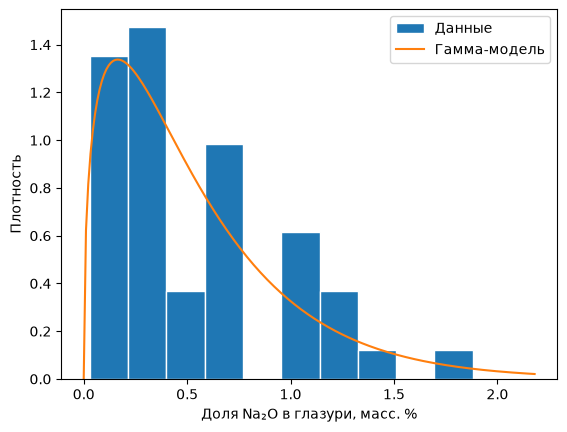

In [76]:
%run ./pylib.py

<a id="models"></a>
### Графики 

- Гистограмма показывает, какие значения встречаются чаще. На диаграмме размаха линия внутри прямоугольника — медиана. Отдельные точки показывают возможные выбросы по правилу $1{,}5\,IQR$, где $IQR=Q_3-Q_1$. Эти точки оставляем в данных.
- При стандартизации вычитаем среднее и делим на выборочное стандартное отклонение: $z=(x-\bar x)/s$. Получаем среднее около 0 и стандартное отклонение 1. Форма гистограммы сохраняется, меняется шкала.
- Нормальное распределение симметрично, его центр — среднее $\mu$, а разброс задаёт стандартное отклонение $\sigma$. Его плотность
  $$f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right).$$
  Если нормальная модель подходит, точки на Q–Q графике примерно ложатся на прямую. Критерий Шапиро — Уилка помогает проверить это численно. При $p<0{,}05$ отвергаем нормальность.

<a id="rv01"></a>
## Random Variable 01 — Na₂O в основе

### Description

Доля оксида натрия в основе выбранного образца. Единица измерения — масс. %.

### EDA & Distribution

,Na₂O в основе
Число значений,44.000
Среднее,0.397
Стандартное отклонение,0.211
Минимум,0.030
Первый квартиль,0.258
Медиана,0.370
Третий квартиль,0.552
Максимум,0.890
Дисперсия,0.045
Асимметрия,0.400


После стандартизации: среднее 0.00, стандартное отклонение 1.00.
Шапиро — Уилк: W = 0.9730, p = 0.3839.


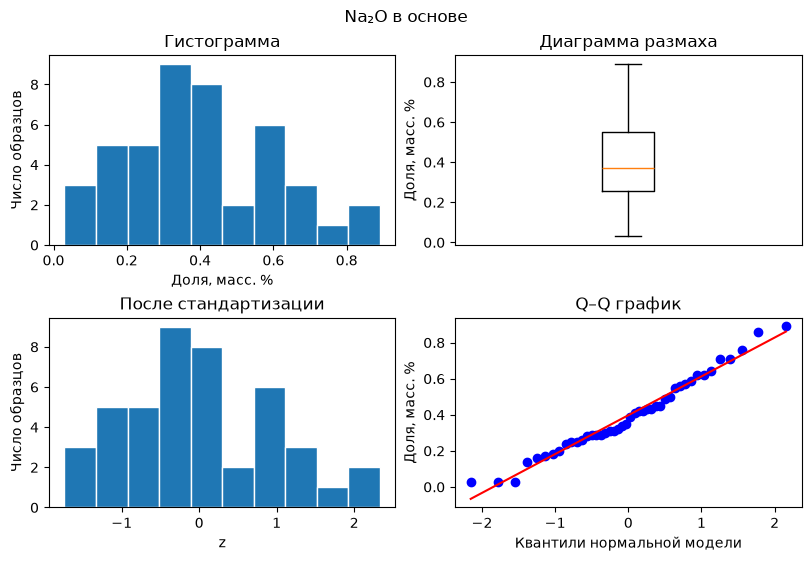

In [77]:
describe_and_plot(data['Na₂O в основе'])

Среднее 0,398 масс. %, медиана 0,370 масс. %. По тесту Шапиро — Уилка ($p=0{,}384$) нет оснований отвергать нормальную модель.

<a id="rv02"></a>
## Random Variable 02 — Na₂O в глазури

### Description

Доля оксида натрия в глазури выбранного образца. Единица измерения — масс. %.

### EDA & Distribution

,Na₂O в глазури
Число значений,44.000
Среднее,0.546
Стандартное отклонение,0.436
Минимум,0.030
Первый квартиль,0.222
Медиана,0.375
Третий квартиль,0.722
Максимум,1.880
Дисперсия,0.190
Асимметрия,1.070


После стандартизации: среднее 0.00, стандартное отклонение 1.00.
Шапиро — Уилк: W = 0.8975, p = 0.0009.


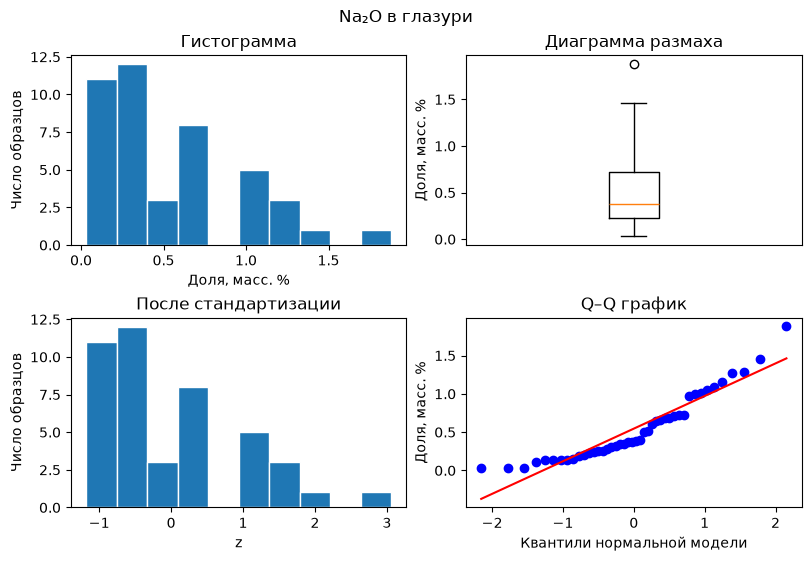

In [78]:
describe_and_plot(data['Na₂O в глазури'])

Среднее 0,546 масс. %, а медиана 0,375 масс. %. На гистограмме заметен правый хвост. При $p=0{,}0009$ отвергаем нормальную модель и пробуем две другие.

При логнормальной модели логарифмы значений должны быть нормальными. Все значения положительны, поэтому берём логарифм и снова применяем Шапиро — Уилка.

Ещё один вариант — гамма-распределение. Оно подходит для положительных значений и может иметь правый хвост. У него два параметра: $k$ задаёт форму, $\theta$ — масштаб. Среднее равно $k\theta$, дисперсия — $k\theta^2$. Плотность имеет вид
$$f(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\theta^k},\qquad x>0.$$

Подбираем параметры по данным. Статистика $D$ показывает самое большое расстояние между функцией распределения модели и данными. Чтобы найти $p$, 1 999 раз создаём пробную выборку из модели и каждый раз заново подбираем параметры. Это параметрический бутстрэп. [Документация SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html)

Для логнормальной модели $p=0{,}0137$, поэтому её отвергаем. Для гамма-модели $p=0{,}7605$. По этому тесту гамма-распределение можно использовать как приближение.

<a id="rv03"></a>
## Random Variable 03 — Al₂O₃ в основе

### Description

Доля оксида алюминия в основе выбранного образца. Единица измерения — масс. %.

### EDA & Distribution

,Al₂O₃ в основе
Число значений,44.000
Среднее,21.812
Стандартное отклонение,2.301
Минимум,17.650
Первый квартиль,19.590
Медиана,21.835
Третий квартиль,23.310
Максимум,26.480
Дисперсия,5.293
Асимметрия,0.001


После стандартизации: среднее -0.00, стандартное отклонение 1.00.
Шапиро — Уилк: W = 0.9735, p = 0.4002.


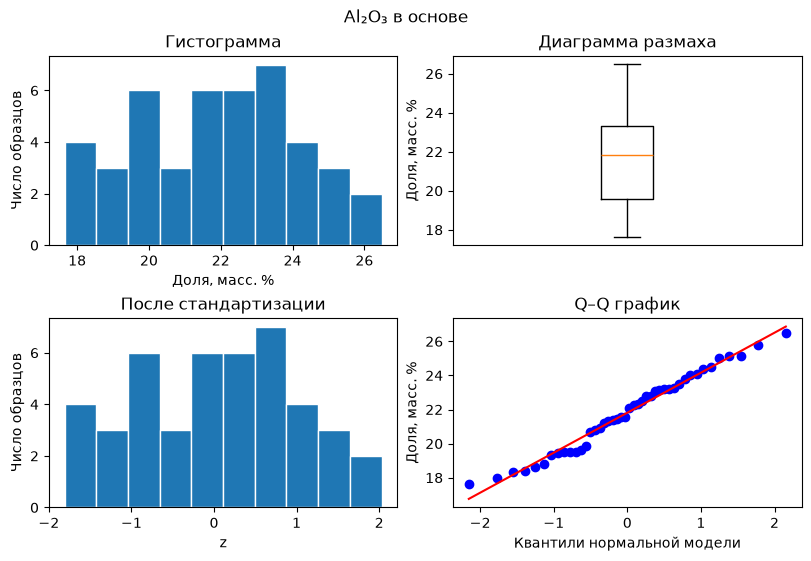

In [79]:
describe_and_plot(data['Al₂O₃ в основе'])

Среднее и медиана почти совпадают (21,812 и 21,835 масс. %). При $p=0{,}400$ нет оснований отвергать нормальную модель.

<a id="rv04"></a>
## Random Variable 04 — Al₂O₃ в глазури

### Description

Доля оксида алюминия в глазури выбранного образца. Единица измерения — масс. %.

### EDA & Distribution

,Al₂O₃ в глазури
Число значений,44.000
Среднее,13.110
Стандартное отклонение,0.849
Минимум,11.300
Первый квартиль,12.708
Медиана,13.005
Третий квартиль,13.715
Максимум,14.760
Дисперсия,0.720
Асимметрия,-0.305


После стандартизации: среднее -0.00, стандартное отклонение 1.00.
Шапиро — Уилк: W = 0.9721, p = 0.3587.


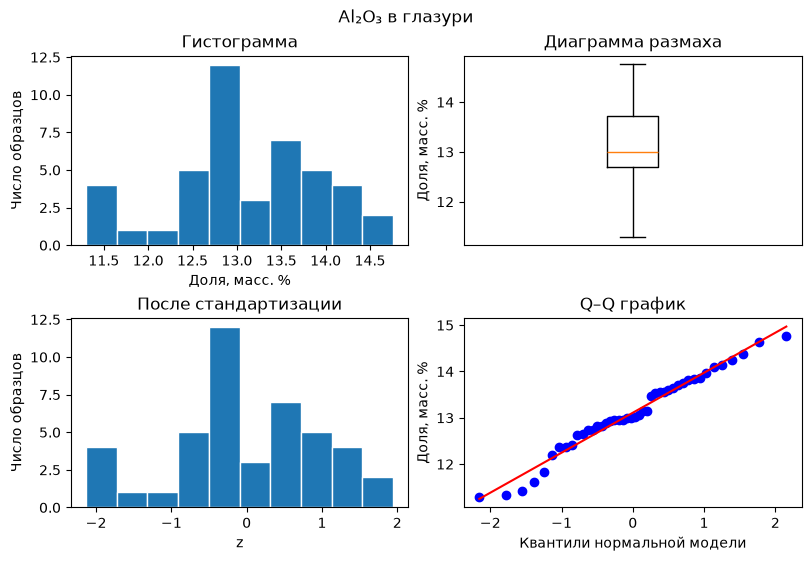

In [80]:
describe_and_plot(data['Al₂O₃ в глазури'])

Среднее 13,110 масс. %. Значения разбросаны меньше, чем в основе: стандартные отклонения 0,849 и 2,301 п.п. соответственно. При $p=0{,}359$ нет оснований отвергать нормальную модель.

<a id="dependence"></a>
## Зависимость

Диаграмм рассеяния: каждая точка — один образец. Коэффициент Пирсона ($r$) показывает, насколько заметна линейная связь. 

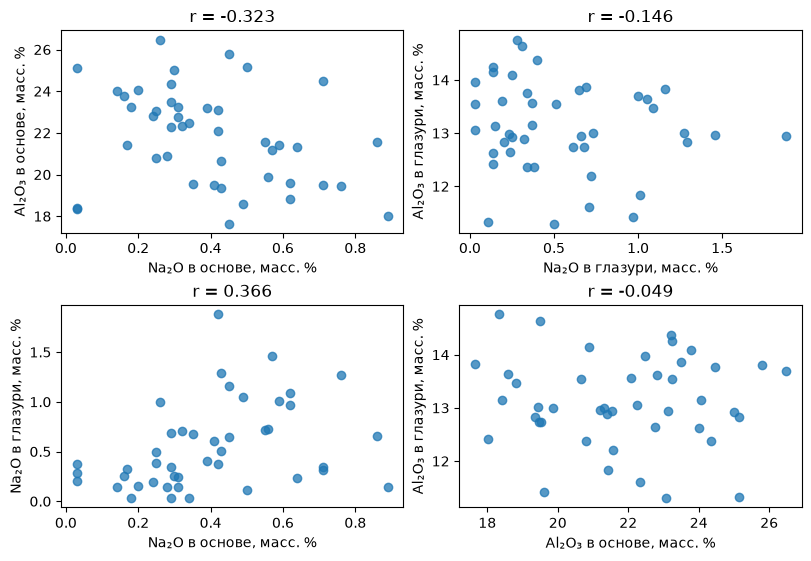

In [81]:
plot_pairs(data, [(0, 2), (1, 3), (0, 1), (2, 3)])

Теперь проверим независимость для всех шести пар. Сначала считаем меру связи на исходных парах. Затем перемешиваем значения одной величины между образцами и снова считаем её. Если при перемешивании такая же или более сильная связь встречается редко, это аргумент против независимости.

В качестве меры используем квадрат дистанционной ковариации. Он сравнивает расстояния между наблюдениями и позволяет заметить связь, даже если она нелинейная. В коде сначала вычитаем из каждого расстояния среднее по его строке и столбцу, затем добавляем общее среднее. После этого перемножаем две матрицы поэлементно и берём среднее. 

In [82]:
dependence = test_independence(data)

Делаем шесть проверок, поэтому учитываем, что маленькое $p$ может случайно встретиться хотя бы в одной. По методу Холма сортируем $p$ от меньшего к большему, умножаем на 6, 5 и так далее, а затем не даём скорректированным значениям уменьшаться. Сравниваем их с 0,05.

In [83]:
dependence = holm_correction(dependence)
dependence

,Величина 1,Величина 2,r Пирсона,p,p с поправкой Холма
0,Na₂O в основе,Na₂O в глазури,0.3663,0.0030,0.018
1,Na₂O в основе,Al₂O₃ в основе,-0.3228,0.0064,0.032
2,Na₂O в глазури,Al₂O₃ в основе,-0.2942,0.0150,0.060
3,Na₂O в глазури,Al₂O₃ в глазури,-0.1463,0.5118,1.000
4,Na₂O в основе,Al₂O₃ в глазури,-0.1450,0.8028,1.000
5,Al₂O₃ в основе,Al₂O₃ в глазури,-0.0486,0.8740,1.000


Независимость отвергается для двух пар: Na₂O в основе и глазури ($p=0{,}018$) и Na₂O с Al₂O₃ внутри основы ($p=0{,}032$). Для остальных пар данных недостаточно для вывода о зависимости. Перестановочный тест предполагает, что при независимости строки можно свободно перемешивать. Если группы образцов различаются по составу, они тоже могут влиять на результат.

<a id="sampling"></a>
## Выборки и оценки

Проверим, насколько хорошо небольшая выборка описывает все 44 образца. Для каждой схемы берём 20 идентификаторов. Каждый раз вместе берём все четыре измерения образца.

- **С возвращением** один и тот же образец может попасть в выборку несколько раз.
- **Без возвращения** один образец может попасть только один раз.

Сравниваем среднее и дисперсию выборки со значениями по полному CSV. В дисперсии полного набора делим на $N=44$. В выборочной дисперсии делим на $n-1$. Для отбора без возвращения дополнительно умножаем выборочную дисперсию на $(N-1)/N$, чтобы она в среднем оценивала дисперсию с делителем $N$.

In [84]:
compare_sampling(data)

С возвращением: 13 разных образцов из 20.
Без возвращения: 20 разных образцов из 20.


,Среднее по CSV,Среднее · с возвращением,Среднее · без возвращения
Na₂O в основе,0.3975,0.377,0.4160
Na₂O в глазури,0.5459,0.637,0.5255
Al₂O₃ в основе,21.8120,21.622,21.5340
Al₂O₃ в глазури,13.1098,13.167,12.8440


,Дисперсия по CSV,Дисперсия · с возвращением,Дисперсия · без возвращения
Na₂O в основе,0.0437,0.0421,0.0427
Na₂O в глазури,0.1858,0.1315,0.1518
Al₂O₃ в основе,5.1730,5.8383,6.2490
Al₂O₃ в глазури,0.7038,0.8985,0.7855


,Среднее по CSV,Дисперсия по CSV,Среднее · с возвращением,Дисперсия · с возвращением,Среднее · без возвращения,Дисперсия · без возвращения
Na₂O в основе,0.397500,0.043714,0.377,0.042064,0.4160,0.042726
Na₂O в глазури,0.545909,0.185801,0.637,0.131506,0.5255,0.151780
Al₂O₃ в основе,21.812045,5.172971,21.622,5.838291,21.5340,6.249025
Al₂O₃ в глазури,13.109773,0.703843,13.167,0.898517,12.8440,0.785546


## Состоятельность оценок

Состоятельность означает, что с ростом выборки оценка с большой вероятностью оказывается близка к нужному значению. При отборе с возвращением это следует из закона больших чисел. Среднее значений и среднее их квадратов приближаются к значениям по всему CSV, а через них считается выборочная дисперсия. Без возвращения из этого файла можно взять максимум 44 образца. Тогда вся таблица попадёт в выборку и ошибки исчезнут.

Чтобы увидеть это на данных, для каждого размера делаем 2 000 повторов. Считаем RMSE: возводим ошибки в квадрат, усредняем и берём корень. Чем ниже линия, тем меньше ошибка.

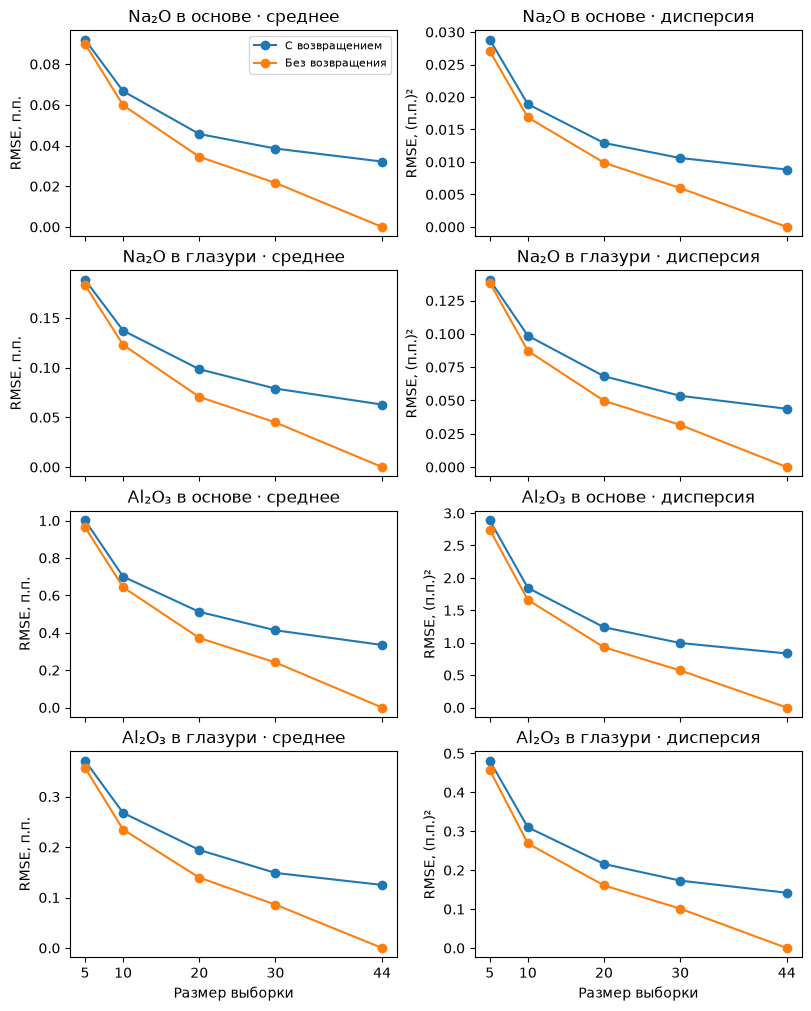

In [85]:
errors, sizes = compute_rmse_errors(data)
plot_rmse_errors(data, errors, sizes)

На графиках видно, что ошибки уменьшаются с ростом выборки. Для среднего теория даёт простое сравнение: при отборе без возвращения дисперсия оценки уменьшается в $(N-n)/(N-1)$ раза. При $n=20$ RMSE среднего должен составить примерно 75% от ошибки при отборе с возвращением. В нашем опыте вышло от 71% до 75% для четырёх величин.

<a id="hypothesis"></a>
## Гипотеза про Na₂O

**Вопрос.** Отличается ли средняя доля Na₂O в глазури и в основе?

- $H_0$. Средняя разность «глазурь минус основа» равна нулю.
- $H_1$. Средняя разность отличается от нуля.

Измерения сделаны на одних и тех же образцах, поэтому используем **парный t-тест**. Он работает с разностями внутри каждой пары. Проверим их на нормальность и будем считать разности разных образцов независимыми. Уровень значимости — 0,05. 

In [86]:
paired_ttest_analysis(data, col1=data.columns[0], col2=data.columns[1]);

Шапиро — Уилк для разностей: p = 0.2756
Средняя разность: 0.148 п.п.
Парный t-тест: t = 2.407, p = 0.0205
95%-й доверительный интервал: от 0.024 до 0.273 п.п.


Для разностей $p=0{,}276$, поэтому тест Шапиро-Уилка не отвергает нормальность. Парный t-тест даёт $p=0{,}0205$. Отвергаем $H_0$ на уровне 0,05. В этих данных доля Na₂O в глазури в среднем выше на 0,148 процентного пункта.

<a id="resume"></a>
## Общие выводы

1. Для Na₂O в основе и Al₂O₃ в обеих частях можно использовать нормальную модель как приближение. Для Na₂O в глазури подошла гамма-модель.
2. Связь обнаружилась между долями Na₂O в основе и глазури и между двумя оксидами внутри основы.
3. Чем больше выборка, тем точнее мы оцениваем среднее и дисперсию. При отборе без возвращения среднее обычно оценивается точнее при том же размере выборки.
4. По 44 парам доля Na₂O в глазури оказалась в среднем выше, чем в основе. Эти образцы были заранее отобраны составителями набора, поэтому вывод про всю историческую керамику из них сделать трудно.

### table

| id | notebook_link | comment |
|---|---|---|
| EDA | [1](#rv01), [2](#rv02), [3](#rv03), [4](#rv04) | | Графики и статистики четырёх величин |
| Distribution | [Модели](#models) | | Стандартизация и проверка распределений |
| Independence | [Зависимость](#dependence) | | Пирсон и перестановочный тест |
| Estimations | [Выборки и оценки](#sampling) | | Две схемы отбора, ошибки оценок |
| Hypothesis | [Гипотеза](#hypothesis) | | Парный t-тест |
| Resume | [Выводы](#resume) | | Итоги |